# Spectral Filtering of Calaveras topography

7/17/24 Maddie Schwarz

In [1]:
import os
import sys
sys.path.append('Modules/demAnalysisComponents/')
import dem as dpy
import fftGrid as fg
from matplotlib import pyplot as plt
import numpy as np
from importlib import reload
%matplotlib inline
%matplotlib widget
import math

/opt/conda/envs/rgr/lib/python3.8/site-packages/osgeo/gdal.py:287: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


raster min:  243.7393798828125
raster max:  456.36077880859375
raster no data value:  -9999.0
ndv data type:  <class 'float'>
DEM rows:  1000
DEM columns:  1000
DEM total # of cells:  1000000
DEM max value:  456.36077880859375
DEM min value:  243.7393798828125
DEM sample size:  1000000


Text(0.5, 1.0, 'Histogram of DEM elevation values')

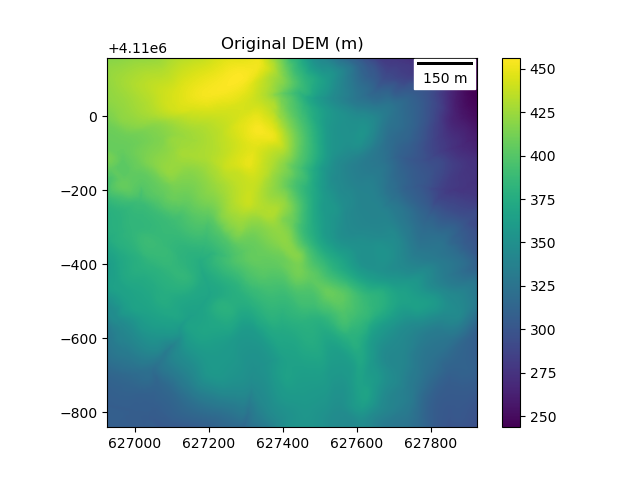

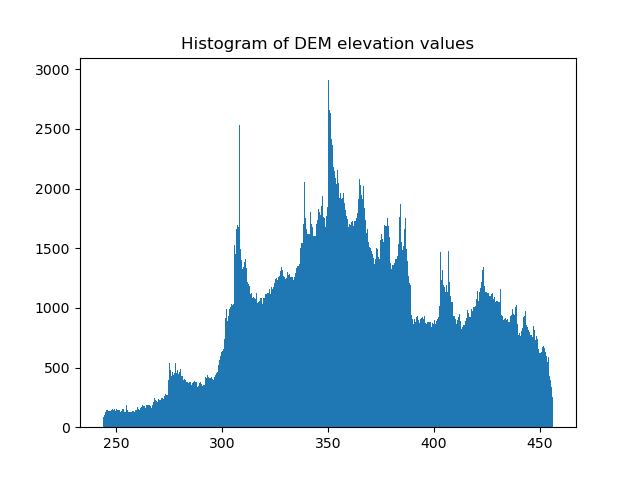

In [2]:
# Import Digital elevation model Raster
testDataPath = 'Calaveras3DEP_TILES/3DEP_tiles_1k/DEM_3DEP1m_03_02.tif' #'testData/rasterData/OD_10m_microTest.tif' 'Calaveras_Oct24/DSM_qcalSmall1_10m.tif' #
# Create an instance of a dem grid object
testDEM = dpy.demGrid([], rasterPath = testDataPath)

# Inspect DEM values for |proper display in plots
print('raster min: ',testDEM.min())
print('raster max: ',testDEM.max())
ndv = testDEM.ndv(testDataPath)
print('raster no data value: ', ndv)
print('ndv data type: ', type(ndv))


#Remove noDataValue
testDEM.getGridExtent()
ndv = ndv
testDEM_n = testDEM.returnMaskedGrid(testDEM!=ndv)


print('DEM rows: ',testDEM_n.shape[0])
print('DEM columns: ',testDEM_n.shape[-1])
print('DEM total # of cells: ', (testDEM_n.shape[0]*testDEM_n.shape[-1]))

DEMsample_size = testDEM_n.shape[0]*testDEM_n.shape[-1] #(np.size(testDEM_n.getGridCoords()))
print('DEM max value: ',testDEM_n.max())
print('DEM min value: ', testDEM_n.min())
print('DEM sample size: ', DEMsample_size)

# Plot DEM and histogram of elevation values
ep = testDEM_n.plotGrid(logTransform=False, addColorBar = True, addScaleBar=True)
ep.set_title('Original DEM (m)')
hp = testDEM_n.plotHistogram(axs = None, bins = int(math.sqrt(DEMsample_size)), range=(testDEM_n.min(),testDEM_n.max()))
hp.set_title('Histogram of DEM elevation values')




/workspaces/rgr/src/Modules/demAnalysisComponents/fftGrid.py:231: RuntimeWarning: divide by zero encountered in divide
  self.L = 1.0 / np.sqrt(FX*FX + FY*FY)
/workspaces/rgr/src/Modules/demAnalysisComponents/fftGrid.py:145: RuntimeWarning: divide by zero encountered in divide
  demGridInstance = (np.real(np.fft.ifft2(self.grid))/self._windowMultiplier) + self._detrendGrid
/workspaces/rgr/src/Modules/demAnalysisComponents/fftGrid.py:145: RuntimeWarning: invalid value encountered in divide
  demGridInstance = (np.real(np.fft.ifft2(self.grid))/self._windowMultiplier) + self._detrendGrid


(-0.02, 0.02)

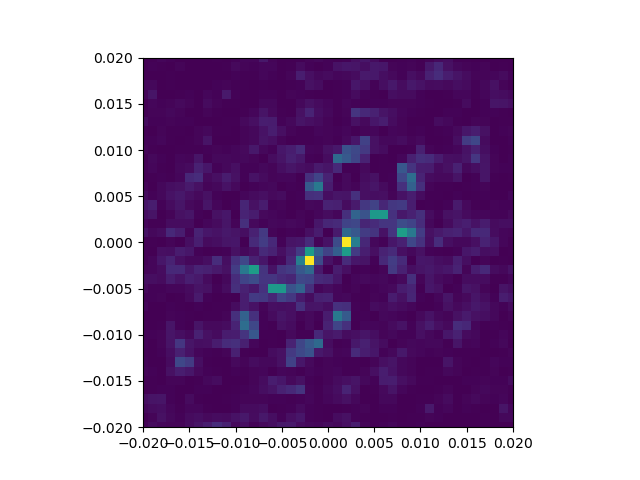

In [3]:

#Create an instance of a dem grid object
testDEM_n = dpy.demGrid([],rasterPath=testDataPath)

#Get a fft dem
newSpecDEM = fg.fftGrid(testDEM_n, applyHannWindow=True)

nMedianBins = 20

#Calculate a number of random permutations of topography using the diamond-square algorithm
nPermutations = 10#In practice this number should be large, thousands if your able
#Fit roughness to the DEM by creating some test random DEMs

H_fit = newSpecDEM.calcBestFittingDiamondSquareRoughness(nBinsForMedian = nMedianBins,nRoughnessValuesToTest = 15)


#Compare these values to the average of 50 of the random grids
#this will first find the best fitting roughness unless its specified
HtoUse = H_fit #This value obtained a couple cells up



specPowerPermutations = newSpecDEM.calcDiamondSquareComparisonAnomalyGrid(nPermutations = nPermutations,
                                                                          roughness=HtoUse)

#Plot the anomalies
axs, countGrid, normGrid = newSpecDEM.plotSpectralAnomalies(logTransform = False)

#Zoom in on the center of the image
wavelengthRangeToCenter = 50
axs.set_xlim(-1/wavelengthRangeToCenter,1/wavelengthRangeToCenter)
axs.set_ylim(-1/wavelengthRangeToCenter,1/wavelengthRangeToCenter)


/workspaces/rgr/src/Modules/demAnalysisComponents/fftGrid.py:681: RuntimeWarning: invalid value encountered in scalar divide
  length_theta_grid[i,j] = np.sum(weights*gridToInterpolate)/np.sum(weights)


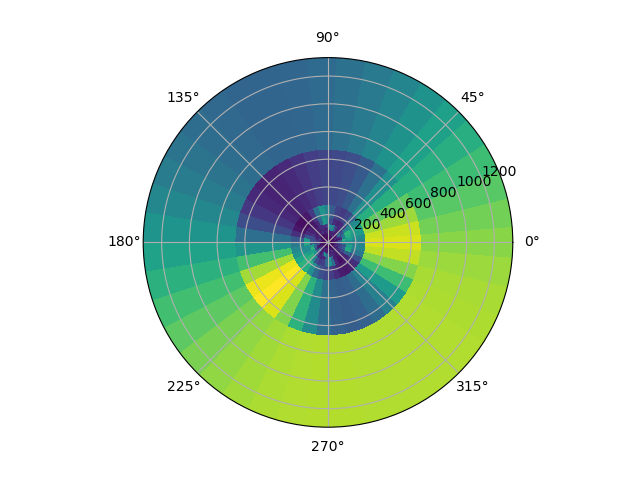

In [4]:
#Create an instance of a dem grid object
testDEM_n = dpy.demGrid([],rasterPath=testDataPath)

newSpecDEM = fg.fftGrid(testDEM_n, applyHannWindow=True) 
#Set a roughness value (rather than searching for the best fit), this is about what was fit for the example grid
#in above cells
roughnessForComparison = H_fit
#Calculate a number of random permutations of topography using the diamond-square algorithm
nPermutations = 10 #In practice this number should be large, thousands if your able - but this is slow
specPowerPermutations = newSpecDEM.calcDiamondSquareComparisonAnomalyGrid(roughness = roughnessForComparison,
                                                                          nPermutations = nPermutations)

axs = newSpecDEM.plotRadialSpectralAnomalies() #Ls = np.linspace(100, 2500, 80), nThetaBins = 80, vmin = 3, vmax = 50)


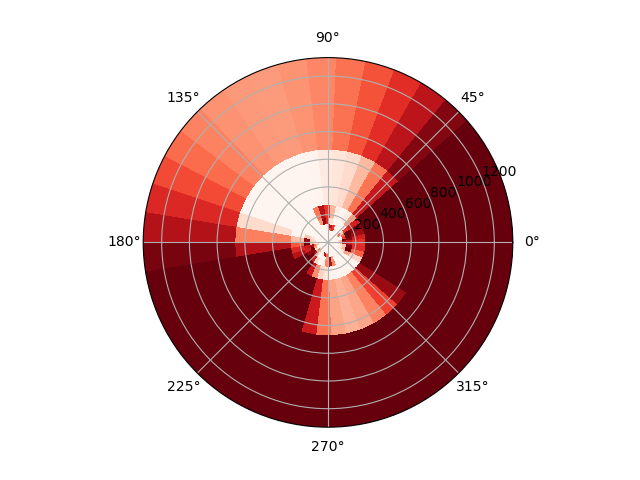

In [5]:
#Below needs to be updated for this function
f, axs = plt.subplots(1, 1, subplot_kw=dict(projection='polar'))

#Plot the plot
axs.pcolor(newSpecDEM.Thetagrid, newSpecDEM.Lgrid,newSpecDEM._length_theta_anomalyGrid, vmin = 3, vmax = 10, cmap = 'Reds')

/workspaces/rgr/src/Modules/demAnalysisComponents/fftGrid.py:667: RuntimeWarning: divide by zero encountered in divide
  freq = 1.0/L
/workspaces/rgr/src/Modules/demAnalysisComponents/fftGrid.py:668: RuntimeWarning: invalid value encountered in multiply
  X_p,Y_p = freq*np.cos(Theta), freq*np.sin(Theta)


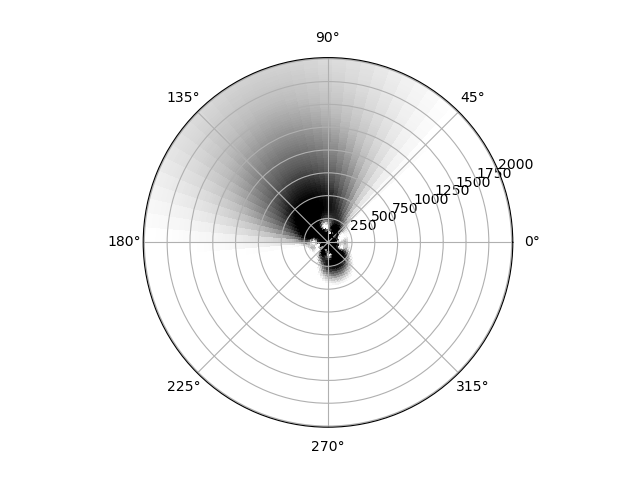

In [6]:
axs = newSpecDEM.plotRadialSpectralAnomalies(Ls = np.linspace(0, 2000, 80), nThetaBins = 80, vmin = 3, vmax = 10, cmap='Greys_r')

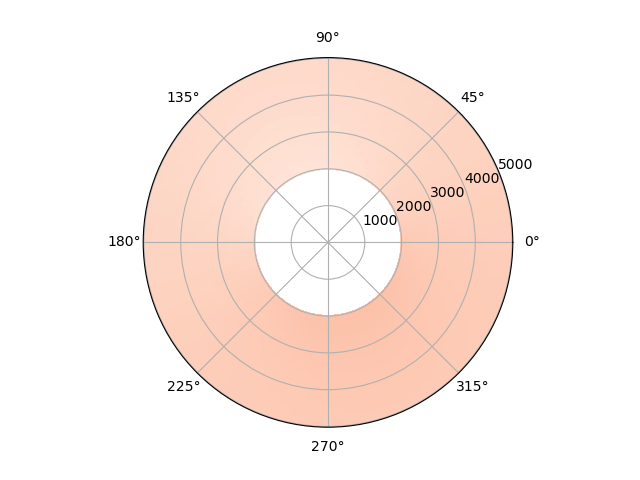

In [7]:
axs = newSpecDEM.plotRadialSpectralAnomalies(Ls = np.linspace(2000, 5000, 80), nThetaBins = 80, vmin = 3, vmax = 50, cmap='Reds')

306.5759568810819
421.1155346970619


Text(0.5, 1.0, 'Histogram of wavelengths in the range 2000-5000 m')

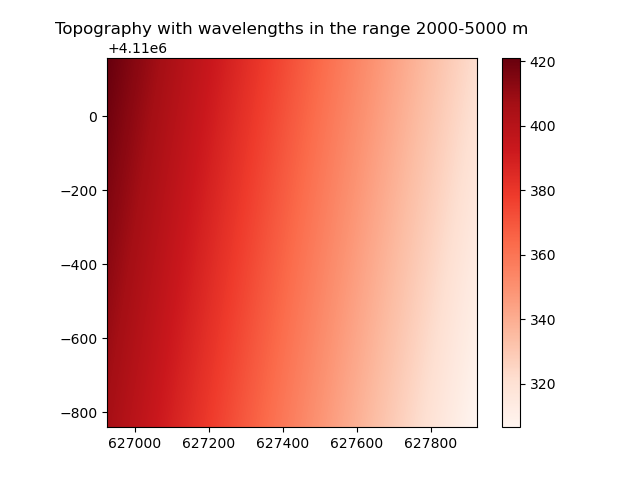

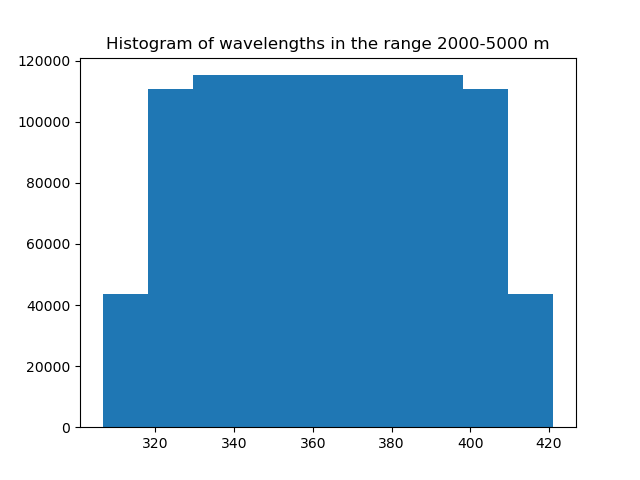

In [8]:
testDEM = dpy.demGrid([],rasterPath=testDataPath)
#newSpecDEM = fg.fftGrid(testDEM_n, applyHannWindow=True) 

'''To conduct spectral filtering, create an fftGrid instance.'''
# Define min and max wavelengths for filtering fft grid
maximumWavelength = 5000
minimumWavelength = 2000

# Filter for middle wavelengths of topography
bp = fg.fftGrid(testDEM) 
bp.addFilter_bandPass(minimumWavelength, maximumWavelength, sigma_wavelength = 30) 
bp.applyFilters() 
bpDEM = bp.inverseTransform() 
print(bpDEM.min())
print(bpDEM.max())

bpp = bpDEM.plotGrid( logTransform=False, addColorBar = True, addScaleBar=False, cmap='Reds')
bpp.set_title('Topography with wavelengths in the range {}-{} m'.format(minimumWavelength, maximumWavelength)) 
bph = bpDEM.plotHistogram()
bph.set_title('Histogram of wavelengths in the range {}-{} m'.format(minimumWavelength, maximumWavelength))

In [9]:
#bpDEM.saveGrid('Calaveras_Oct24/spec1w2000to5000.tif','GTiff')

296.16659085041647
414.5225820883692


Text(0.5, 1.0, 'Histogram of wavelengths in the range 1000-2000 m')

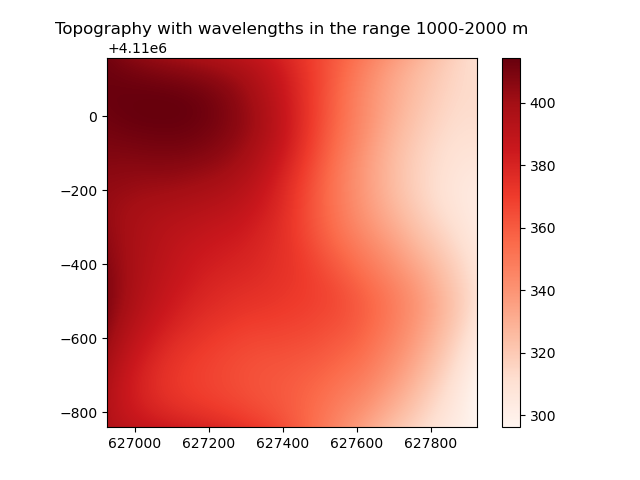

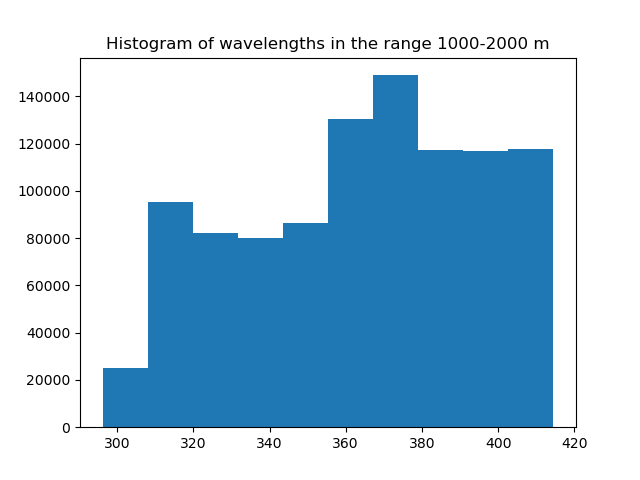

In [9]:
testDEM = dpy.demGrid([],rasterPath=testDataPath)
#newSpecDEM = fg.fftGrid(testDEM_n, applyHannWindow=True) 

'''To conduct spectral filtering, create an fftGrid instance.'''
# Define min and max wavelengths for filtering fft grid
maximumWavelength = 2000
minimumWavelength = 1000

# Filter for middle wavelengths of topography
ap = fg.fftGrid(testDEM) 
ap.addFilter_bandPass(minimumWavelength, maximumWavelength, sigma_wavelength = 500)
ap.applyFilters() 
apDEM = ap.inverseTransform() 
print(apDEM.min())
print(apDEM.max())

app = apDEM.plotGrid(logTransform=False, addColorBar = True, addScaleBar=False, cmap='Reds')
app.set_title('Topography with wavelengths in the range {}-{} m'.format(minimumWavelength, maximumWavelength)) 
aph = apDEM.plotHistogram()
aph.set_title('Histogram of wavelengths in the range {}-{} m'.format(minimumWavelength, maximumWavelength))

290.46711023252954
424.294874617313


Text(0.5, 1.0, 'Histogram of wavelengths in the range 1000-5000 m')

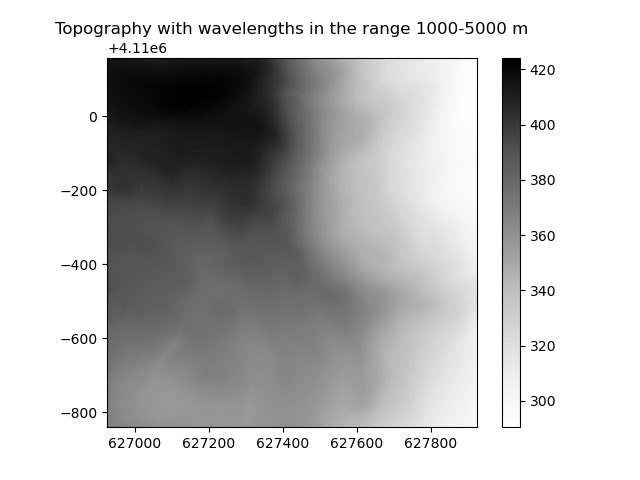

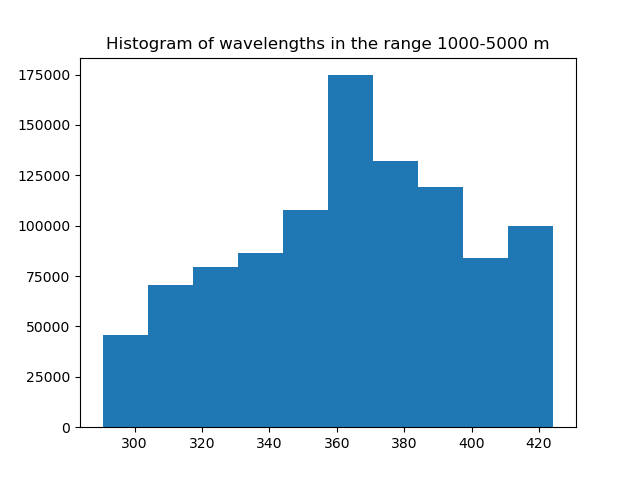

In [10]:
testDEM = dpy.demGrid([],rasterPath=testDataPath)
#newSpecDEM = fg.fftGrid(testDEM_n, applyHannWindow=True) 

'''To conduct spectral filtering, create an fftGrid instance.'''
# Define min and max wavelengths for filtering fft grid
maximumWavelength = 5000
minimumWavelength = 1000
# Filter for middle wavelengths of topography
cp = fg.fftGrid(testDEM) 
cp.addFilter_bandPass(minimumWavelength, maximumWavelength, sigma_wavelength = (minimumWavelength-maximumWavelength)/2) 
cp.applyFilters() 
cpDEM = cp.inverseTransform() 
print(cpDEM.min())
print(cpDEM.max())

cpp = cpDEM.plotGrid(logTransform=False, addColorBar = True, addScaleBar=False, cmap='Greys')
cpp.set_title('Topography with wavelengths in the range {}-{} m'.format(minimumWavelength, maximumWavelength)) 
cph = cpDEM.plotHistogram()
cph.set_title('Histogram of wavelengths in the range {}-{} m'.format(minimumWavelength, maximumWavelength))

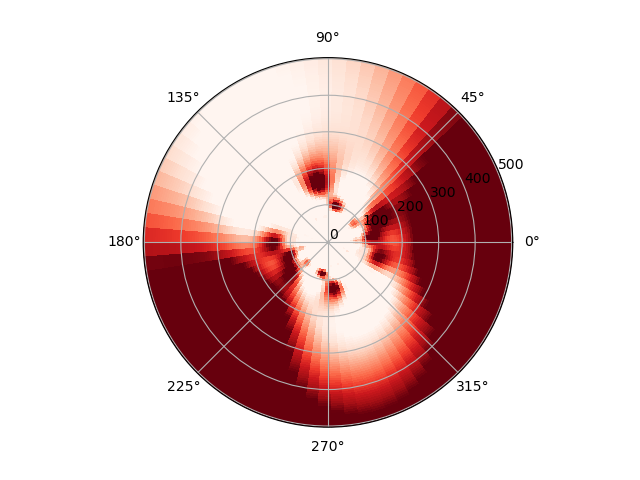

In [11]:
axs = newSpecDEM.plotRadialSpectralAnomalies(Ls = np.linspace(0, 500, 80), nThetaBins = 80, vmin = 3, vmax = 10, cmap='Reds')

284.7093964032118
443.65189742116536


Text(0.5, 1.0, 'Histogram of wavelengths in the range 200-500 m')

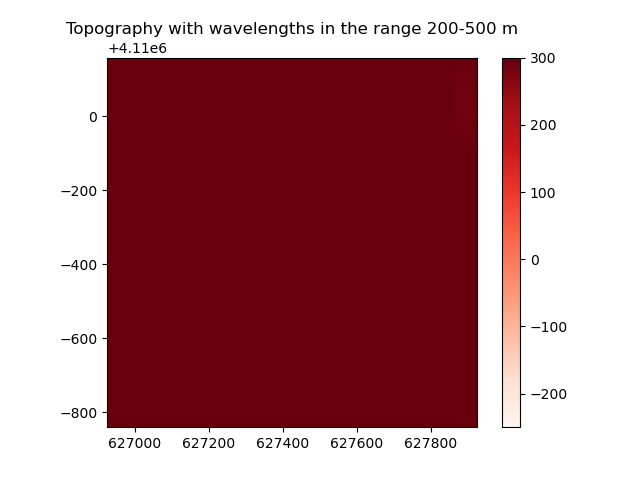

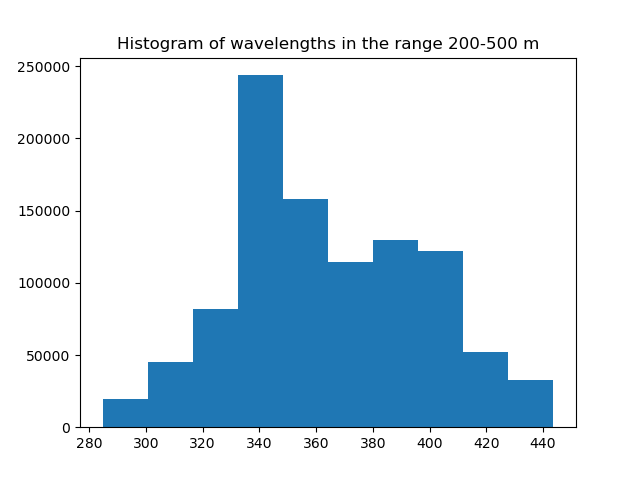

In [25]:
testDEM = dpy.demGrid([],rasterPath=testDataPath)
#newSpecDEM = fg.fftGrid(testDEM_n, applyHannWindow=True) 

'''To conduct spectral filtering, create an fftGrid instance.'''
# Define min and max wavelengths for filtering fft grid
maximumWavelength = 500
minimumWavelength = 200

# Filter for middle wavelengths of topography
dp = fg.fftGrid(testDEM) 
dp.addFilter_bandPass(minimumWavelength, maximumWavelength, sigma_wavelength=200) 
dp.applyFilters() 
dpDEM = dp.inverseTransform() 
print(dpDEM.min())
print(dpDEM.max())

dpp = dpDEM.plotGrid(vmin=-250, vmax=300, logTransform=False, addColorBar = True, addScaleBar=False, cmap='Reds')
dpp.set_title('Topography with wavelengths in the range {}-{} m'.format(minimumWavelength, maximumWavelength)) 
dph = dpDEM.plotHistogram()
dph.set_title('Histogram of wavelengths in the range {}-{} m'.format(minimumWavelength, maximumWavelength))

<Axes: >

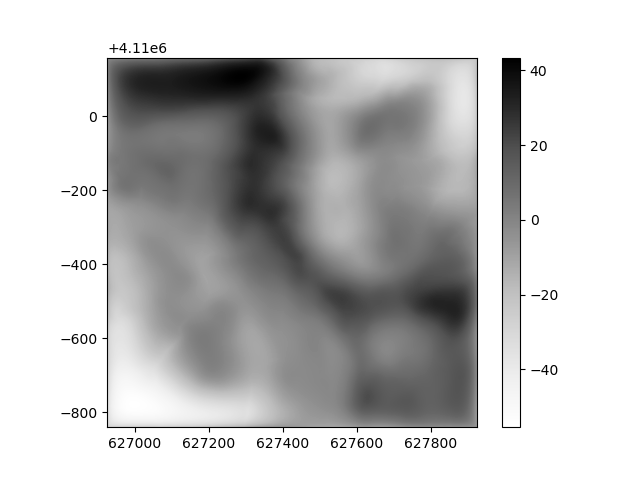

In [26]:
dpDEM = dpDEM-bpDEM
dpDEM.plotGrid( logTransform=False, addColorBar = True, addScaleBar=False, cmap='Greys')

In [27]:
#dpDEM.saveGrid('Calaveras_Oct24/spec1w200to500.tif','GTiff')

Text(0.5, 1.0, 'Topography with wavelengths less than 10 m')

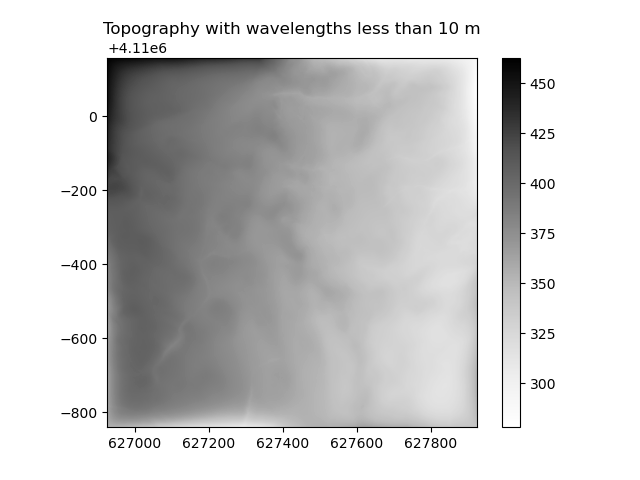

In [28]:
# wavelengths less than 10m
#Second plot - the long wavelengths of the topography
testDEM = dpy.demGrid([],rasterPath=testDataPath)
highWavelength = 10

lp = fg.fftGrid(testDEM)
lp.addFilter_highPass(highWavelength,sigma_wavelength = (minimumWavelength-maximumWavelength)/2)
lp.applyFilters()
lpDEM = lp.inverseTransform()
lpp = lpDEM.plotGrid(logTransform=False, addColorBar = True, addScaleBar=False, cmap='Greys')
lpp.set_title('Topography with wavelengths less than {} m'.format(highWavelength)) 

Text(0.5, 1.0, 'Topography with wavelengths greater than 2000 m')

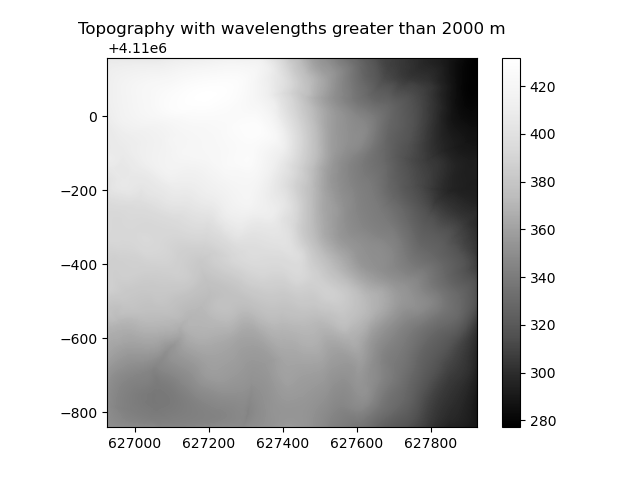

In [29]:

#Second plot - the long wavelengths of the topography
highWavelength = 2000
testDEM = dpy.demGrid([],rasterPath=testDataPath)
hi = fg.fftGrid(testDEM)
hi.addFilter_lowPass(highWavelength, sigma_wavelength=1500)
hi.applyFilters()
hiDEM = hi.inverseTransform()
hip = hiDEM.plotGrid(logTransform=False, addColorBar = True, addScaleBar=False, cmap='Greys_r')
hip.set_title('Topography with wavelengths greater than {} m'.format(highWavelength)) 

In [ ]:
#hiDEM.saveGrid('Calaveras_Oct24/greaterthan2000.tif','GTiff')

<Axes: >

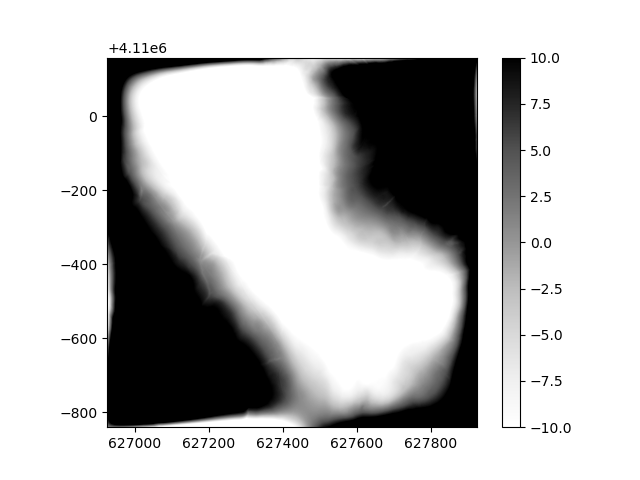

In [30]:
# Subtract out long wavelength from short wavelength (less than 10m) raster to see finer features
less10m = lpDEM-hiDEM
less10m.plotGrid(vmin=-10, vmax=10, logTransform=False, addColorBar = True, addScaleBar=False, cmap='Greys')

In [76]:
#less10m.saveGrid('Calaveras_Oct24/spec1less10m_2.tif','GTiff')

/workspaces/rgr/src/Modules/demAnalysisComponents/fftGrid.py:681: RuntimeWarning: invalid value encountered in scalar divide
  length_theta_grid[i,j] = np.sum(weights*gridToInterpolate)/np.sum(weights)


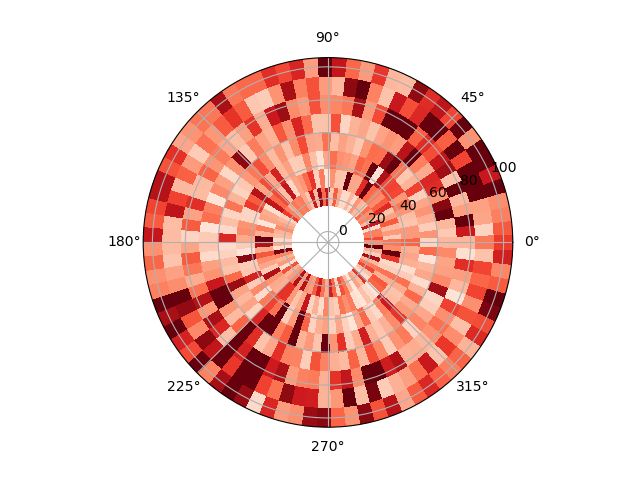

In [77]:
axs = newSpecDEM.plotRadialSpectralAnomalies(Ls = np.linspace(-1, 100, 10), nThetaBins = 80, vmin = 0, vmax = 5, cmap='Reds')

filtered specDEM max value:  (11163682.562352117-233019.11963595095j)
filtered specDEM min value:  (-12981358.009415621-4158608.981601555j)
final specDEM max value:  2010.1390978196875
final specDEM min value:  -27106.805186341455


Text(0.5, 1.0, 'Histogram of wavelengths')

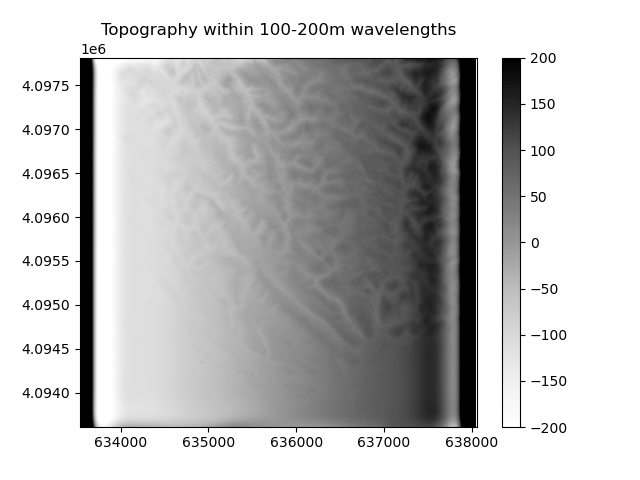

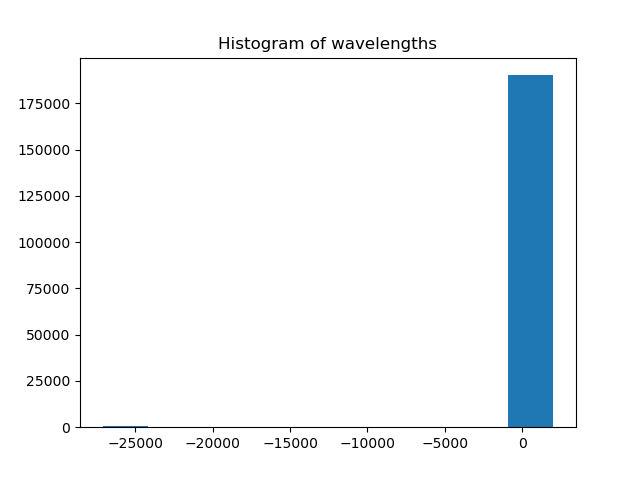

In [78]:
testDEM = dpy.demGrid([],rasterPath=testDataPath)
#newSpecDEM = fg.fftGrid(testDEM_n, applyHannWindow=True) 

specDEM = fg.fftGrid(testDEM) 
'''To conduct spectral filtering, create an fftGrid instance.'''
# Define min and max wavelengths for filtering fft grid
maximumWavelength = 200
minimumWavelength = 100

# Filter for long wavelengths of topography
specDEM.addFilter_bandPass(minimumWavelength, maximumWavelength, sigma_wavelength = 200) 
specDEM.applyFilters()
print('filtered specDEM max value: ', specDEM.max())
print('filtered specDEM min value: ', specDEM.min())

#Reverse the transform
filteredDEM = specDEM.inverseTransform().removePlaneFromGrid()
print('final specDEM max value: ', filteredDEM.max())
print('final specDEM min value: ', filteredDEM.min())

#Plot the filtered product + histogram of wavelengths
axs = filteredDEM.plotGrid(vmin=-200, vmax=200, logTransform=False, addColorBar = True, addScaleBar=False, cmap='Greys')
axs.set_title('Topography within 100-200m wavelengths')
fhp = filteredDEM.plotHistogram()
fhp.set_title('Histogram of wavelengths')

In [79]:
#less10m.saveGrid('Calaveras_Oct24/spec1less10m_2.tif','GTiff')

filtered specDEM max value:  (13577319.777876602+94435.4286071126j)
filtered specDEM min value:  (-11534020.623169426-5494989.086155522j)
final specDEM max value:  2942.862392867736
final specDEM min value:  -29880.820888998634


Text(0.5, 1.0, 'Histogram of wavelengths')

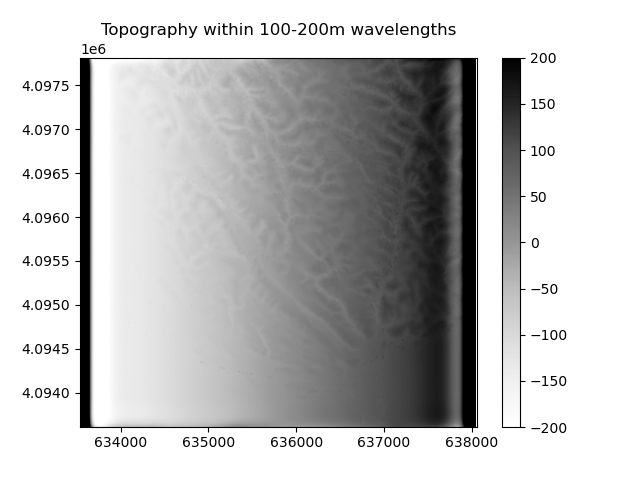

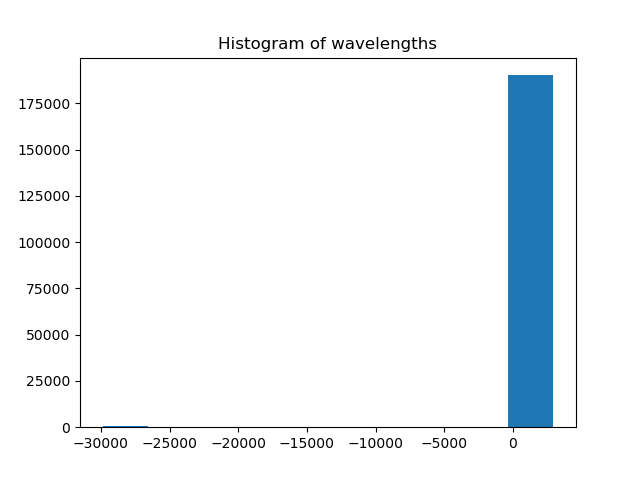

In [80]:
testDEM = dpy.demGrid([],rasterPath=testDataPath)
#newSpecDEM = fg.fftGrid(testDEM_n, applyHannWindow=True) 

specDEM = fg.fftGrid(testDEM) 
'''To conduct spectral filtering, create an fftGrid instance.'''
# Define min and max wavelengths for filtering fft grid
maximumWavelength = 100
minimumWavelength = 10

# Filter for long wavelengths of topography
specDEM.addFilter_bandPass(minimumWavelength, maximumWavelength, sigma_wavelength = 200) 
specDEM.applyFilters()
print('filtered specDEM max value: ', specDEM.max())
print('filtered specDEM min value: ', specDEM.min())

#Reverse the transform
filteredDEM = specDEM.inverseTransform().removePlaneFromGrid()
print('final specDEM max value: ', filteredDEM.max())
print('final specDEM min value: ', filteredDEM.min())

#Plot the filtered product + histogram of wavelengths
axs = filteredDEM.plotGrid(vmin=-200, vmax=200, logTransform=False, addColorBar = True, addScaleBar=False, cmap='Greys')
axs.set_title('Topography within 100-200m wavelengths')
fhp = filteredDEM.plotHistogram()
fhp.set_title('Histogram of wavelengths')